---
title: "L3-05 · Eigenvectors and observables"
short_title: "Eigenvectors and observables"
subtitle: "An eigenvector is a direction a matrix only stretches; for a Hermitian matrix these directions are perpendicular, the matrix is a weighted sum of projections onto them, and the weights are the only values a measurement can return."
description: "Find the eigenvalues and eigenvectors of a 2 by 2 matrix, and use the eigenvalues of a Hermitian matrix as the possible results of an ideal measurement, with probabilities and an expectation value computed from a state."
tags: [level-3, coursebook]
---

(lesson-l3-05)=

:::{div}
:class: qcai-meta
![Level 3 icon](../../_static/icons/qicon-level-3.svg) **Level 3 · High-school bridge** · about 90 minutes  
**Big idea.** An eigenvector is a direction a matrix only stretches; for a Hermitian matrix these directions are perpendicular, the matrix is a weighted sum of projections onto them, and the weights are the only values a measurement can return.  
**Before this lesson.** [L3-02](#lesson-l3-02), [L3-03](#lesson-l3-03)  
**Lab.** [Qubits and the Bloch sphere](../../labs/05-qubit-bloch.ipynb)
:::

## What you will be able to do

- Solve $\det(A - \lambda I) = 0$ for a $2 \times 2$ matrix and find a nonzero eigenvector for each eigenvalue.
- Prove that a Hermitian matrix has real eigenvalues and that eigenvectors for different eigenvalues are orthogonal.
- Write a symmetric matrix as $\sum_k \lambda_k P_k$ and use it to compute $Au$ piece by piece.
- Compute outcome probabilities $|\langle v_k|\psi\rangle|^2$ and the expectation $\langle A\rangle = \psi^\dagger A\psi$, and explain why the expectation need not be a possible outcome.

## Why this matters

Apply the matrix $\begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}$ to a vector and the result usually points somewhere new: $(1, 0)$ goes to $(2, 1)$. Yet a few special directions come out pointing exactly where they went in, only longer or shorter. Find those directions and the matrix stops being a table of four numbers. It becomes a list of stretch factors along a few perpendicular axes, and every computation with it gets simpler.

Quantum theory takes this one step further. A measurable quantity, such as the spin of an electron along an axis, is described by a Hermitian matrix. A measurement never returns an arbitrary number: it returns one of the eigenvalues, and the state decides how likely each one is. A puzzle to keep in mind: if a measurement can only give 3 or 1, how can its average be 2, and what does that 2 tell you?

:::{dropdown} Key terms

**Eigenvector**
: A nonzero vector $v$ with $Av = \lambda v$: the matrix sends it along its own line.

**Eigenvalue**
: The number $\lambda$ in $Av = \lambda v$, the stretch factor along that line (negative means the arrow flips).

**Characteristic polynomial**
: $\det(A - \lambda I)$; its roots are exactly the eigenvalues.

**Hermitian matrix**
: A square matrix equal to its conjugate transpose, $A = A^\dagger$; for real entries this means symmetric.

**Projector**
: $P = vv^\dagger$ for a unit vector $v$; it keeps the part of a vector along $v$ and removes the rest.

**Observable**
: A Hermitian matrix whose eigenvalues are the possible results of an ideal measurement.

**Expectation value**
: The probability-weighted average $\langle A\rangle = \sum_k \lambda_k p_k = \psi^\dagger A\psi$ of the outcomes.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l3_05 as _lessonfigs

## Directions a matrix does not turn

In [L3-03](#lesson-l3-03) a matrix was a transformation of the plane. Most vectors change direction under it. This lesson is about the ones that do not.

:::{prf:definition} Eigenvector and eigenvalue
:label: def-l3-05-eigen
Let $A$ be an $n \times n$ matrix. A **nonzero** vector $v$ is an **eigenvector** of $A$ with **eigenvalue** $\lambda$ if $Av = \lambda v$. The zero vector is excluded because $A0 = \lambda 0$ for every $\lambda$, which would say nothing. Any nonzero multiple $cv$ is again an eigenvector with the same $\lambda$, so an eigenvector really names a line through the origin.
:::

:::{figure} ../../_static/animations/l3_05_eigen_directions.mp4
:alt: A grid, a unit circle and five arrows transformed by the matrix with rows (2, 1) and (1, 2). Three arrows leave their dashed lines; the arrow along (1, 1) triples and the arrow along (-1, 1) stays put. Then the characteristic polynomial is solved.
:width: 100%

The matrix $A = \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}$ moves the whole plane. Only arrows on the two eigenlines stay on their lines: $(1, 1)$ is stretched by 3, $(-1, 1)$ by 1.
:::

:::{dropdown} What the animation shows
Five arrows start on dashed lines through the origin: $(1, 0)$, $(0, 1)$, $(0.5, -1)$, $(1, 1)$ and $(-1, 1)$, together with the unit circle and a grid. The matrix $A$ with rows $(2, 1)$ and $(1, 2)$ is applied smoothly. The arrow $(1, 0)$ ends at $(2, 1)$, off its line, so it is not an eigenvector; $(0, 1)$ and $(0.5, -1)$ also leave their lines. The arrow $(1, 1)$ ends at $(3, 3)$ on its own line, so $Av_1 = 3v_1$, and $(-1, 1)$ does not move at all, so $Av_2 = 1\,v_2$. The circle becomes an ellipse whose axes have half-lengths 3 and 1 along these two lines. A side panel then derives the eigenvalues: $Av = \lambda v$ is the same as $(A - \lambda I)v = 0$, which has a nonzero solution exactly when $\det(A - \lambda I) = 0$; here that is $(2 - \lambda)^2 - 1 = 0$, that is $\lambda^2 - 4\lambda + 3 = 0$, which factors as $(\lambda - 3)(\lambda - 1) = 0$, giving $\lambda_1 = 3$ and $\lambda_2 = 1$.
:::


In [2]:
_show(_lessonfigs.eigen_hunt())

**Explore.** Turn the unit vector $v$ with the slider. The red arrow is $Av$; the right panel shows how far $Av$ is turned away from $v$. The turn is zero exactly at $45^\circ$ and $135^\circ$, the two eigen-directions.

:::{dropdown} What the figure shows
The first panel shows the unit circle (dotted), its image under $A$ (an ellipse), the two dashed eigenlines along $(1, 1)$ and $(1, -1)$, the blue unit vector $v = (\cos\theta, \sin\theta)$ and the red vector $Av$. The second panel plots the signed angle from $v$ to $Av$ for $\theta$ from $0^\circ$ to $180^\circ$; it equals $\arctan\big(\cos 2\theta / (2 + \sin 2\theta)\big)$, starts at about $26.6^\circ$ at $\theta = 0$, crosses zero at $45^\circ$ (where $Av = 3v$) and at $135^\circ$ (where $Av = v$), and stays between $-30^\circ$ and $30^\circ$.
:::


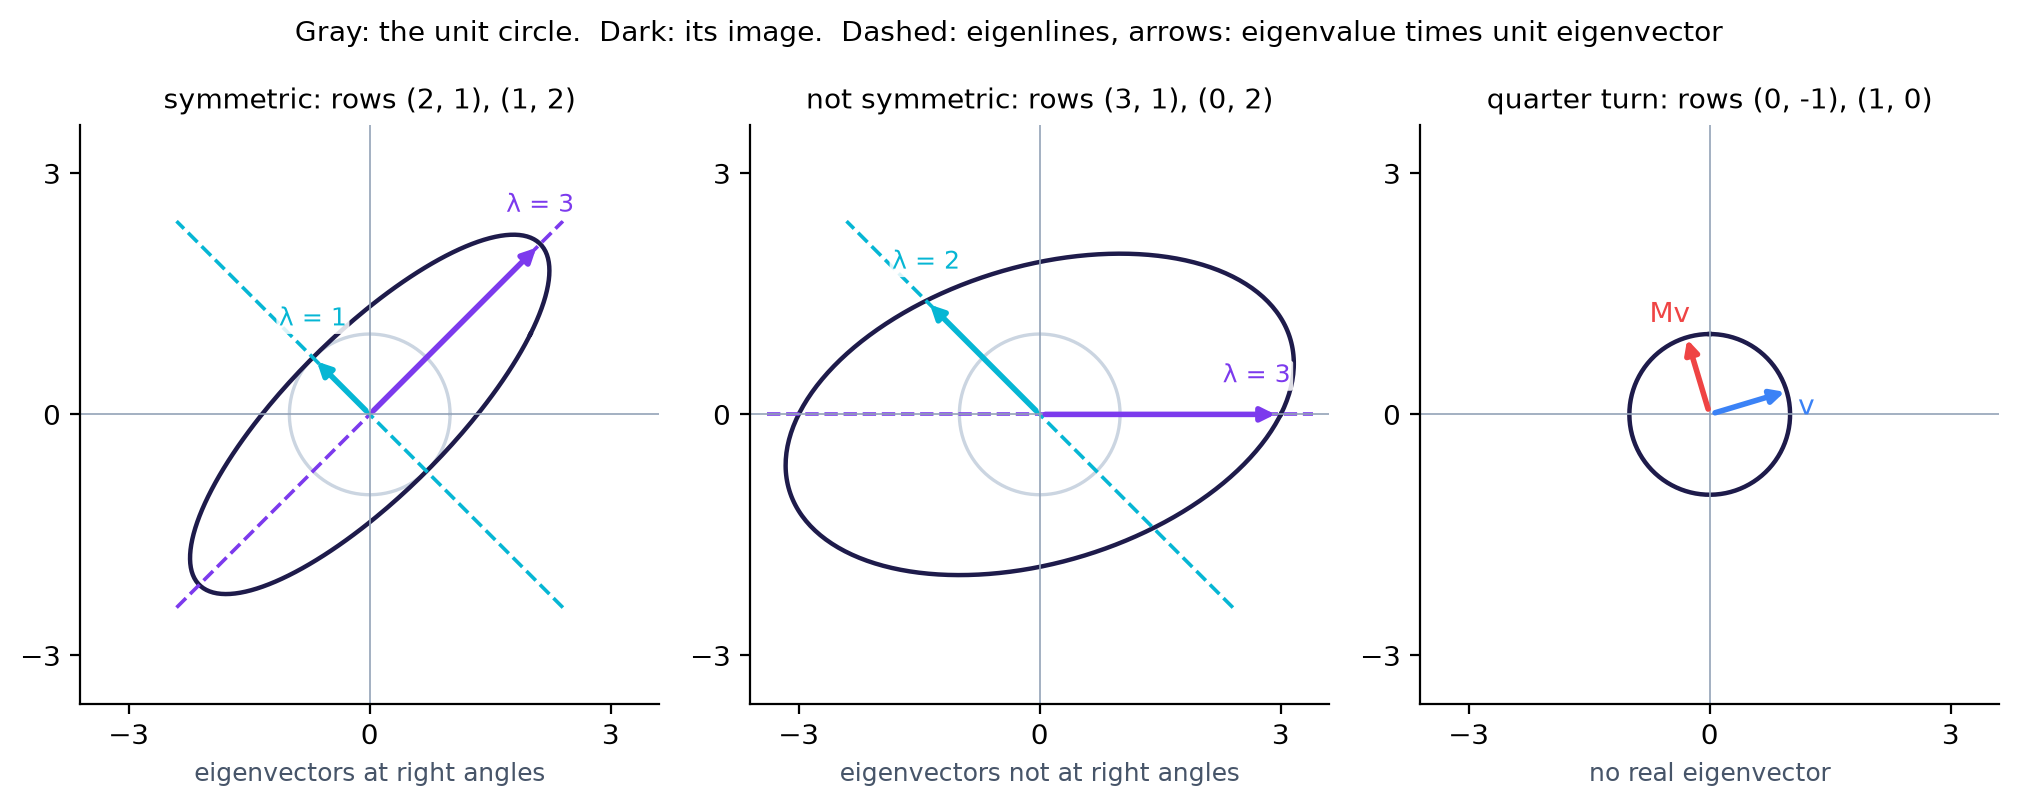

In [3]:
_show_mpl(_lessonfigs.three_maps())

*Three matrices acting on the unit circle. A symmetric matrix has perpendicular eigenlines along the axes of the ellipse. The non-symmetric matrix $\begin{pmatrix} 3 & 1 \\ 0 & 2 \end{pmatrix}$ still has two eigenlines, along $(1, 0)$ and $(1, -1)$, but they are not perpendicular. A quarter turn moves every direction, so it has no real eigenvector at all.*

## Finding eigenvalues

:::{prf:proposition} Eigenvalues are roots of the characteristic polynomial
:label: prop-l3-05-charpoly
A number $\lambda$ is an eigenvalue of the $2 \times 2$ matrix $A$ if and only if $\det(A - \lambda I) = 0$.
:::

:::{prf:proof}
$Av = \lambda v$ means $(A - \lambda I)v = 0$, so we need a nonzero solution of $Mv = 0$ for $M = A - \lambda I = \begin{pmatrix} a & b \\ c & d \end{pmatrix}$. If $ad - bc \ne 0$, then $M$ has the inverse $\frac{1}{ad - bc}\begin{pmatrix} d & -b \\ -c & a \end{pmatrix}$, and $Mv = 0$ forces $v = M^{-1}0 = 0$. If $ad - bc = 0$, a nonzero solution exists: $v = (-b, a)$ gives $Mv = (-ab + ba,\ -cb + da) = (0, 0)$, and if $a = b = 0$ use $v = (d, -c)$ instead, or any vector when $M = 0$. So a nonzero solution exists exactly when $\det M = 0$.
:::

$$
\det(A - \lambda I) = \det\begin{pmatrix} 2 - \lambda & 1 \\ 1 & 2 - \lambda \end{pmatrix} = (2 - \lambda)^2 - 1 = \lambda^2 - 4\lambda + 3 = (\lambda - 3)(\lambda - 1)
$$ (eq-l3-05-charpoly)

By [](#eq-l3-05-charpoly) the eigenvalues of $A$ are 3 and 1. To find an eigenvector, solve $(A - \lambda I)v = 0$. For $\lambda = 3$: $\begin{pmatrix} -1 & 1 \\ 1 & -1 \end{pmatrix}v = 0$ gives $v_1 = (1, 1)$. For $\lambda = 1$: $\begin{pmatrix} 1 & 1 \\ 1 & 1 \end{pmatrix}v = 0$ gives $v_2 = (1, -1)$. Check: $A(1, 1) = (3, 3)$ and $A(1, -1) = (1, -1)$. Normalized, $v_1 = (1, 1)/\sqrt2$ and $v_2 = (1, -1)/\sqrt2$.

:::{prf:remark} A shortcut for 2 by 2 matrices
For $A = \begin{pmatrix} a & b \\ c & d \end{pmatrix}$, $\det(A - \lambda I) = \lambda^2 - (a + d)\lambda + (ad - bc)$. So the eigenvalues add to the trace $a + d$ and multiply to the determinant $ad - bc$. For our $A$: $3 + 1 = 4 = 2 + 2$ and $3 \cdot 1 = 3 = 4 - 1$. A quick check worth doing every time.
:::

## Hermitian matrices and the spectral theorem

:::{prf:definition} Conjugate transpose, inner product, Hermitian
:label: def-l3-05-hermitian
For a complex matrix $A$, the **conjugate transpose** $A^\dagger$ has entries $(A^\dagger)_{jk} = \overline{A_{kj}}$. For column vectors $u, v$ we use the inner product $\langle u|v\rangle = u^\dagger v = \sum_k \overline{u_k}\, v_k$, which conjugates the **first** slot (the physics convention). It is the same number that [L3-02](#lesson-l3-02) wrote as $\langle u, v\rangle$; the bar notation is the one used from Level 5 on. Then $\langle v|v\rangle = \sum_k |v_k|^2 \ge 0$. A matrix is **Hermitian** if $A^\dagger = A$. A real matrix is Hermitian exactly when it is symmetric.
:::

:::{prf:theorem} Eigenvalues and eigenvectors of a Hermitian matrix
:label: thm-l3-05-hermitian
Let $A = A^\dagger$. (a) Every eigenvalue of $A$ is real. (b) If $Au = \lambda u$ and $Av = \mu v$ with $\lambda \ne \mu$, then $\langle u|v\rangle = 0$.
:::

:::{prf:proof}
The key fact is $\langle u|Av\rangle = u^\dagger A v = (A^\dagger u)^\dagger v = \langle Au|v\rangle$ when $A = A^\dagger$. (a) Let $Av = \lambda v$ with $v \ne 0$. Then $\langle v|Av\rangle = \lambda\langle v|v\rangle$, while $\langle Av|v\rangle = \bar\lambda\langle v|v\rangle$ because the first slot is conjugated. These are equal and $\langle v|v\rangle > 0$, so $\lambda = \bar\lambda$: $\lambda$ is real. (b) Now $\langle u|Av\rangle = \mu\langle u|v\rangle$ and $\langle Au|v\rangle = \bar\lambda\langle u|v\rangle = \lambda\langle u|v\rangle$, using (a). Equal again, so $(\mu - \lambda)\langle u|v\rangle = 0$, and since $\mu \ne \lambda$, $\langle u|v\rangle = 0$.
:::

:::{prf:theorem} Spectral theorem (finite dimensions)
:label: thm-l3-05-spectral
Every $n \times n$ Hermitian matrix has an orthonormal basis of eigenvectors $v_1, \dots, v_n$ with real eigenvalues $\lambda_1, \dots, \lambda_n$, and $A = \sum_{k=1}^{n} \lambda_k\, v_k v_k^\dagger$.
:::

:::{prf:proof}
We prove the case this lesson uses: $n = 2$ with two different eigenvalues $\lambda_1 \ne \lambda_2$ (the general case, including repeated eigenvalues, is proved by induction on $n$ in [@nielsenchuang], section 2.1). Take unit eigenvectors $v_1, v_2$. By the previous theorem they are orthogonal, so they form an orthonormal basis of $\mathbb{C}^2$. Let $P_k = v_k v_k^\dagger$. Every vector splits as $x = \langle v_1|x\rangle v_1 + \langle v_2|x\rangle v_2 = P_1x + P_2x$, so $P_1 + P_2 = I$. Then $A = A(P_1 + P_2)$, and $AP_kx = \langle v_k|x\rangle Av_k = \lambda_k P_kx$, so $A = \lambda_1 P_1 + \lambda_2 P_2$.
:::

$$
A = 3P_1 + 1P_2, \qquad P_1 = \tfrac12\begin{pmatrix} 1 & 1 \\ 1 & 1 \end{pmatrix}, \quad P_2 = \tfrac12\begin{pmatrix} 1 & -1 \\ -1 & 1 \end{pmatrix}
$$ (eq-l3-05-spectral)

:::{figure} ../../_static/animations/l3_05_spectral_pieces.mp4
:alt: The vector u = (2, 0) is split into pieces along the two eigenlines, the piece along (1, 1) is tripled, and the pieces are added back to give (4, 2).
:width: 100%

Equation [](#eq-l3-05-spectral) as a picture: to apply $A$, split $u$ along the eigenlines, stretch each piece by its eigenvalue, and add.
:::

:::{dropdown} What the animation shows
On a plane with the eigenline of $\lambda_1 = 3$ along $(1, 1)$ and the eigenline of $\lambda_2 = 1$ along $(1, -1)$, the blue vector $u = (2, 0)$ is drawn. The formulas $A = 3P_1 + 1P_2$ with $P_1 = \tfrac12\begin{pmatrix} 1 & 1 \\ 1 & 1 \end{pmatrix}$ and $P_2 = \tfrac12\begin{pmatrix} 1 & -1 \\ -1 & 1 \end{pmatrix}$ appear. Dashed perpendiculars drop from the tip of $u$ to each eigenline, giving the pieces $P_1u = (1, 1)$ and $P_2u = (1, -1)$. The first piece is stretched by 3 to $(3, 3)$; the second is kept, since its eigenvalue is 1. A parallelogram adds them: $Au = (3, 3) + (1, -1) = (4, 2)$, and the direct product $(2 \cdot 2 + 1 \cdot 0,\ 1 \cdot 2 + 2 \cdot 0) = (4, 2)$ agrees.
:::

:::{tip} Why the decomposition is useful
Powers and functions of $A$ act on each piece separately: $A^m = 3^m P_1 + 1^m P_2$, because $P_1P_2 = 0$ and $P_k^2 = P_k$. For example $A^{10} = 59049\,P_1 + P_2$. The same idea defines $e^{-iAt}$ in quantum dynamics later in the course.
:::

## Observables: eigenvalues as outcomes

In quantum theory a state is a unit vector $\psi$ ([L2-09](#lesson-l2-09)), and a measurable quantity is a Hermitian matrix. The next definition is a rule of the theory (the Born rule for an ideal projective measurement), not something we derive here; Level 5 develops it.

:::{prf:definition} Ideal measurement of an observable
:label: def-l3-05-measure
Let $A = \sum_k \lambda_k v_kv_k^\dagger$ be Hermitian with distinct eigenvalues and orthonormal eigenvectors $v_k$, and let $\psi$ be a unit vector. An ideal measurement of $A$ returns the value $\lambda_k$ with probability $p_k = |\langle v_k|\psi\rangle|^2$, and no other value. These $p_k$ are nonnegative and add to $\sum_k |\langle v_k|\psi\rangle|^2 = \langle\psi|\psi\rangle = 1$.
:::

:::{prf:proposition} The expectation value
:label: prop-l3-05-expect
The average outcome is $\langle A\rangle = \sum_k \lambda_k p_k = \psi^\dagger A\,\psi$.
:::

:::{prf:proof}
Insert the spectral decomposition: $\psi^\dagger A\psi = \sum_k \lambda_k\, \psi^\dagger v_k\, v_k^\dagger\psi = \sum_k \lambda_k\, \overline{\langle v_k|\psi\rangle}\,\langle v_k|\psi\rangle = \sum_k \lambda_k |\langle v_k|\psi\rangle|^2 = \sum_k \lambda_k p_k$. Expectation and variance of general random variables are the subject of [L3-07](#lesson-l3-07).
:::

$$
\psi = (\cos t, \sin t): \quad p(3) = |\langle v_1|\psi\rangle|^2 = \frac{1 + \sin 2t}{2}, \qquad \langle A\rangle = 3\,p(3) + 1\,p(1) = 2 + \sin 2t
$$ (eq-l3-05-expect)

To see [](#eq-l3-05-expect): $\langle v_1|\psi\rangle = (\cos t + \sin t)/\sqrt2$, whose square is $(1 + 2\sin t\cos t)/2 = (1 + \sin 2t)/2$. Directly, $\psi^{T}A\psi = 2\cos^2 t + 2\sin t\cos t + 2\sin^2 t = 2 + \sin 2t$. At $t = 0$ the outcomes 3 and 1 are equally likely and $\langle A\rangle = 2$: an average that is never observed in a single shot.

:::{figure} ../../_static/animations/l3_05_outcomes_average.mp4
:alt: A state arrow turns around a circle with two dashed eigenlines; two bars at outcomes 1 and 3 change height, and a red dot for the expectation slides between 1 and 3.
:width: 100%

As the state $\psi = (\cos t, \sin t)$ turns, the chances of the two outcomes trade off and the expectation $2 + \sin 2t$ slides between them. The possible outcomes themselves never change.
:::

:::{dropdown} What the animation shows
Left: the unit circle with the eigenlines of $v_1$ (outcome 3) and $v_2$ (outcome 1), the state arrow $\psi = (\cos t, \sin t)$, and dashed perpendiculars from its tip to both lines. Right: an outcome axis from 0 to 4 with a bar at 3 of height $p(3) = |\langle v_1|\psi\rangle|^2 = \frac{1 + \sin 2t}{2}$ and a bar at 1 of height $p(1) = 1 - p(3)$, and a red dot at $\langle A\rangle = \psi^T A\psi = 3\,p(3) + 1\,p(1) = 2 + \sin 2t$. At $t = 0$ both bars read 0.50 and the dot sits at 2. As $t$ grows to $\pi/4$ the state lies on $v_1$: the bar at 3 reaches 1.00 and the dot reaches 3. At $t = 3\pi/4$ the state lies on $v_2$, the bar at 1 is full and the dot is at 1. At $t = \pi$ the picture is back to equal chances and average 2, while every single measurement still gives 3 or 1.
:::

```{mermaid}
graph LR
  S["state ψ"] --> M{"measure A"}
  M -- "prob p(3)" --> O1["result λ1 = 3<br/>state becomes v1"]
  M -- "prob p(1)" --> O2["result λ2 = 1<br/>state becomes v2"]
  O1 --> R["repeat on fresh copies:<br/>average → ⟨A⟩"]
  O2 --> R
```

*An ideal measurement of $A$ in the state $\psi$: one run gives one eigenvalue, with probability $p_k = |\langle v_k|\psi\rangle|^2$, and leaves the system in the matching eigenvector. Only the average over many freshly prepared copies estimates $\langle A\rangle$.*

:::{important} Single shot versus average
For the Pauli matrix $Z = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}$ and $\psi = (\sqrt{0.8}, \sqrt{0.2})$, the outcomes $+1$ and $-1$ have probabilities 0.8 and 0.2, so $\langle Z\rangle = 0.8 - 0.2 = 0.6$. No single measurement returns 0.6. Estimating 0.6 takes many runs on identically prepared copies, and the error of that estimate is the subject of [L3-10](#lesson-l3-10).
:::

## Compute it

`numpy.linalg.eigh` finds eigenvalues and orthonormal eigenvectors of a symmetric or Hermitian matrix. The cell checks $Av = \lambda v$, orthogonality, the spectral decomposition, the probabilities and the expectation in [](#eq-l3-05-expect), and simulates 10000 ideal measurements.


In [4]:
import numpy as np

A = np.array([[2.0, 1.0], [1.0, 2.0]])
vals, vecs = np.linalg.eigh(A)          # eigh is for symmetric/Hermitian matrices; eigenvalues ascending
print('eigenvalues', vals)
print('unit eigenvectors (columns)')
print(vecs.round(4))
for lam, v in zip(vals, vecs.T):
    print('lambda =', lam, ' A v =', (A @ v).round(4), ' lambda v =', (lam * v).round(4))
print('v_1 . v_2 =', round(float(vecs[:, 0] @ vecs[:, 1]), 12))

# spectral decomposition: A = sum of lambda_k times the projector onto v_k
P = [np.outer(v, v.conj()) for v in vecs.T]
print('sum lambda_k P_k equals A:', np.allclose(sum(l * Pk for l, Pk in zip(vals, P)), A))
u = np.array([2.0, 0.0])
print('A u =', A @ u, ' pieces:', [(l * Pk @ u).round(4) for l, Pk in zip(vals, P)])

# an observable: probabilities and expectation in psi = (cos t, sin t)
t = 0.3
psi = np.array([np.cos(t), np.sin(t)])
probs = np.abs(vecs.conj().T @ psi) ** 2
print('outcomes', vals, 'probabilities', probs.round(4), 'sum', round(float(probs.sum()), 12))
print('<A> = psi^T A psi =', round(float(psi @ A @ psi), 6),
      ' sum lambda p =', round(float(vals @ probs), 6), ' 2 + sin 2t =', round(2 + np.sin(2 * t), 6))

# simulated ideal measurements: every shot returns an eigenvalue
rng = np.random.default_rng(7)
shots = rng.choice(vals, size=10000, p=probs)
print('outcomes seen:', np.unique(shots), ' sample mean of 10000 shots:', round(float(shots.mean()), 4))

eigenvalues [1. 3.]
unit eigenvectors (columns)
[[-0.7071  0.7071]
 [ 0.7071  0.7071]]
lambda = 1.0  A v = [-0.7071  0.7071]  lambda v = [-0.7071  0.7071]
lambda = 3.0  A v = [2.1213 2.1213]  lambda v = [2.1213 2.1213]
v_1 . v_2 = 0.0
sum lambda_k P_k equals A: True
A u = [4. 2.]  pieces: [array([ 1., -1.]), array([3., 3.])]
outcomes [1. 3.] probabilities [0.2177 0.7823] sum 1.0
<A> = psi^T A psi = 2.564642  sum lambda p = 2.564642  2 + sin 2t = 2.564642
outcomes seen: [1. 3.]  sample mean of 10000 shots: 2.5654


For complex vectors the conjugate in $\langle u|v\rangle$ is essential. `np.vdot` conjugates its first argument, matching the convention above. The last lines check the worked example below.


In [5]:
# a complex Hermitian matrix: conjugation matters
Y = np.array([[0, -1j], [1j, 0]])
print('Hermitian:', np.allclose(Y, Y.conj().T))
vals_y, vecs_y = np.linalg.eigh(Y)
print('eigenvalues of Y:', vals_y.round(12))
vp = np.array([1, 1j]) / np.sqrt(2)
vm = np.array([1, -1j]) / np.sqrt(2)
print('Y vp = +vp:', np.allclose(Y @ vp, vp), '  Y vm = -vm:', np.allclose(Y @ vm, -vm))
print('<vp|vm> with conjugation  :', np.vdot(vp, vm))      # np.vdot conjugates its first argument
print('sum vp*vm, no conjugation :', np.sum(vp * vm))

# the worked example: B = [[1, 2], [2, -2]] in the state (1, 0)
B = np.array([[1.0, 2.0], [2.0, -2.0]])
lb, Vb = np.linalg.eigh(B)
pb = np.abs(Vb.T @ np.array([1.0, 0.0])) ** 2
print('B eigenvalues', lb, ' probabilities', pb.round(4), ' <B> =', round(float(lb @ pb), 6))

Hermitian: True
eigenvalues of Y: [-1.  1.]
Y vp = +vp: True   Y vm = -vm: True
<vp|vm> with conjugation  : 0j
sum vp*vm, no conjugation : (0.9999999999999998+0j)
B eigenvalues [-3.  2.]  probabilities [0.2 0.8]  <B> = 1.0


:::{prf:remark} Repeated eigenvalues
If an eigenvalue repeats, its eigenvectors fill a plane (or larger subspace), not a line. For the identity $I$ every nonzero vector is an eigenvector with eigenvalue 1. The measurement rule then uses the projector $P$ onto the whole eigenspace: the probability of that value is $\langle\psi|P|\psi\rangle$. This lesson keeps the eigenvalues distinct.
:::

## Worked example

:::{admonition} Eigenvalues, eigenvectors and an expectation
:class: tip

Let $B = \begin{pmatrix} 1 & 2 \\ 2 & -2 \end{pmatrix}$. Find its eigenvalues and unit eigenvectors, check they are orthogonal, and find the outcome probabilities and $\langle B\rangle$ in the state $\psi = (1, 0)$.

1. Characteristic polynomial: trace $1 + (-2) = -1$ and determinant $-2 - 4 = -6$, so $\det(B - \lambda I) = \lambda^2 + \lambda - 6 = (\lambda - 2)(\lambda + 3)$. Eigenvalues 2 and $-3$.
2. For $\lambda = 2$: $(B - 2I)v = \begin{pmatrix} -1 & 2 \\ 2 & -4 \end{pmatrix}v = 0$ gives $v = (2, 1)$, unit $u_1 = (2, 1)/\sqrt5$. For $\lambda = -3$: $\begin{pmatrix} 4 & 2 \\ 2 & 1 \end{pmatrix}v = 0$ gives $v = (1, -2)$, unit $u_2 = (1, -2)/\sqrt5$.
3. Orthogonality: $(2, 1)\cdot(1, -2) = 2 - 2 = 0$, as the theorem promises for a symmetric matrix.
4. Probabilities in $\psi = (1, 0)$: $p(2) = |\langle u_1|\psi\rangle|^2 = (2/\sqrt5)^2 = 4/5$ and $p(-3) = (1/\sqrt5)^2 = 1/5$; they add to 1.
5. Expectation: $\langle B\rangle = 2 \cdot \tfrac45 + (-3)\cdot\tfrac15 = \tfrac85 - \tfrac35 = 1$. Check: $\psi^T B\psi = B_{11} = 1$.

**Result.** Eigenvalues 2 and $-3$ with orthogonal eigenvectors $(2, 1)/\sqrt5$ and $(1, -2)/\sqrt5$; in the state $(1, 0)$ the outcomes 2 and $-3$ occur with probabilities $4/5$ and $1/5$, and the expectation is 1, which is not itself a possible outcome.
:::

## Exercises

**1. (Core)** Find the eigenvalues and an eigenvector for each eigenvalue of $C = \begin{pmatrix} 4 & 1 \\ 2 & 3 \end{pmatrix}$. Are the eigenvectors orthogonal? Does this contradict the theorem on Hermitian matrices?

:::{dropdown} Solution
Trace 7, determinant $12 - 2 = 10$, so $\lambda^2 - 7\lambda + 10 = (\lambda - 5)(\lambda - 2)$: eigenvalues 5 and 2. For 5: $\begin{pmatrix} -1 & 1 \\ 2 & -2 \end{pmatrix}v = 0$ gives $v = (1, 1)$; check $C(1, 1) = (5, 5)$. For 2: $\begin{pmatrix} 2 & 1 \\ 2 & 1 \end{pmatrix}v = 0$ gives $v = (1, -2)$; check $C(1, -2) = (2, -4)$. Their dot product is $1 - 2 = -1 \ne 0$, so they are not orthogonal. No contradiction: $C$ is not symmetric ($C_{12} = 1 \ne 2 = C_{21}$), so the theorem does not apply.
:::

**2. (Core)** A qubit is in the state $\psi = (\sqrt{0.8}, \sqrt{0.2})$ and $Z = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}$ is measured. List the possible outcomes, their probabilities, and $\langle Z\rangle$ computed two ways.

:::{dropdown} Solution
The eigenvectors of $Z$ are $(1, 0)$ with eigenvalue $1$ and $(0, 1)$ with eigenvalue $-1$. Probabilities: $|\sqrt{0.8}|^2 = 0.8$ for $+1$ and $0.2$ for $-1$. Weighted average: $1(0.8) + (-1)(0.2) = 0.6$. Matrix form: $\psi^T Z\psi = 0.8 - 0.2 = 0.6$. Each single measurement returns $+1$ or $-1$, never 0.6.
:::

**3. (Stretch)** Show that the quarter turn $R = \begin{pmatrix} 0 & -1 \\ 1 & 0 \end{pmatrix}$ has no real eigenvalue, then find its complex eigenvalues and one eigenvector for each.

:::{dropdown} Solution
$\det(R - \lambda I) = \lambda^2 + 1$, which is positive for every real $\lambda$, so there is no real eigenvalue (geometrically, every direction is turned by $90^\circ$). Over $\mathbb{C}$ the roots are $\lambda = \pm i$. For $\lambda = i$: $\begin{pmatrix} -i & -1 \\ 1 & -i \end{pmatrix}v = 0$ gives $v = (1, -i)$; check $R(1, -i) = (i, 1) = i(1, -i)$. For $\lambda = -i$: $v = (1, i)$, and $R(1, i) = (-i, 1) = -i(1, i)$. $R$ is not Hermitian, which is why its eigenvalues can fail to be real.
:::

**4. (Stretch)** Let $Y = \begin{pmatrix} 0 & -i \\ i & 0 \end{pmatrix}$. Show $Y$ is Hermitian, verify that $(1, i)/\sqrt2$ and $(1, -i)/\sqrt2$ are eigenvectors with eigenvalues $+1$ and $-1$, and compute their inner product with and without the complex conjugate. Which answer agrees with the theorem?

:::{dropdown} Solution
$Y^\dagger$ is the transpose $\begin{pmatrix} 0 & i \\ -i & 0 \end{pmatrix}$ with every entry conjugated, which gives back $\begin{pmatrix} 0 & -i \\ i & 0 \end{pmatrix} = Y$. $Y(1, i) = (-i \cdot i,\ i \cdot 1) = (1, i)$, eigenvalue $+1$; $Y(1, -i) = (-i\cdot(-i),\ i) = (-1, i) = -(1, -i)$, eigenvalue $-1$. With the conjugate: $\tfrac12(\bar 1 \cdot 1 + \bar i\cdot(-i)) = \tfrac12(1 + (-i)(-i)) = \tfrac12(1 - 1) = 0$. Without it: $\tfrac12(1 + i(-i)) = \tfrac12(1 + 1) = 1$. Only the conjugated inner product gives 0, as the theorem requires for different eigenvalues.
:::

**5. (Challenge)** Let $A$ be a $2 \times 2$ Hermitian matrix with eigenvalues $\lambda_{\min} \le \lambda_{\max}$. Prove that $\lambda_{\min} \le \psi^\dagger A\psi \le \lambda_{\max}$ for every unit vector $\psi$, and say for which $\psi$ each bound is reached. Use this to give the range of $\langle A\rangle$ for $A = \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}$.

:::{dropdown} Solution
By the proposition, $\psi^\dagger A\psi = \lambda_{\min}p_{\min} + \lambda_{\max}p_{\max}$ with $p$'s nonnegative and adding to 1. A weighted average with such weights lies between the smallest and largest values: $\lambda_{\min} = \lambda_{\min}(p_{\min} + p_{\max}) \le \lambda_{\min}p_{\min} + \lambda_{\max}p_{\max} \le \lambda_{\max}(p_{\min} + p_{\max}) = \lambda_{\max}$. The upper bound is reached when $p_{\max} = 1$, that is when $\psi$ is a unit eigenvector for $\lambda_{\max}$ (up to a phase), and the lower bound when $\psi$ is an eigenvector for $\lambda_{\min}$ (if the eigenvalues are equal, $A = \lambda I$ and every $\psi$ works). For the example, $\langle A\rangle$ ranges over $[1, 3]$; in the family $\psi = (\cos t, \sin t)$ this is $2 + \sin 2t$, which reaches 3 at $t = \pi/4$ and 1 at $t = 3\pi/4$.
:::

**6. (Challenge)** Use the spectral decomposition to compute $A^{10}$ for $A = \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}$ without multiplying ten matrices. Then explain why $P_1P_2 = 0$ and $P_1^2 = P_1$ are needed.

:::{dropdown} Solution
$A = 3P_1 + P_2$ with $P_1 = \tfrac12\begin{pmatrix} 1 & 1 \\ 1 & 1 \end{pmatrix}$ and $P_2 = \tfrac12\begin{pmatrix} 1 & -1 \\ -1 & 1 \end{pmatrix}$. Expanding $(3P_1 + P_2)^{10}$, every product that mixes $P_1$ and $P_2$ contains a factor $P_1P_2$ or $P_2P_1$, which is 0 because $P_1P_2 = v_1(v_1^\dagger v_2)v_2^\dagger = 0$ by orthogonality. The remaining terms are $3^{10}P_1^{10} + P_2^{10} = 3^{10}P_1 + P_2$, using $P_k^2 = v_k(v_k^\dagger v_k)v_k^\dagger = P_k$. So $A^{10} = 59049\,P_1 + P_2 = \tfrac12\begin{pmatrix} 59050 & 59048 \\ 59048 & 59050 \end{pmatrix} = \begin{pmatrix} 29525 & 29524 \\ 29524 & 29525 \end{pmatrix}$.
:::

## Check your understanding

**1. Which vector is an eigenvector of $A = \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}$?**

- **A.** $(1, 2)$
- **B.** $(1, 0)$
- **C.** $(1, -1)$
- **D.** $(0, 1)$

:::{dropdown} Show the answer
**C. $(1, -1)$**

$A(1, -1) = (2 - 1, 1 - 2) = (1, -1)$, so it is an eigenvector with eigenvalue 1. $A(1, 0) = (2, 1)$, $A(0, 1) = (1, 2)$ and $A(1, 2) = (4, 5)$ all point in new directions.
:::

**2. An observable has eigenvalues 3 and 1, and in a certain state its expectation value is 2. What can a single ideal measurement return?**

- **A.** 2 every time
- **B.** 3 or 1, never 2
- **C.** 2 about half the time
- **D.** Any number from 1 to 3

:::{dropdown} Show the answer
**B. 3 or 1, never 2**

An ideal measurement returns an eigenvalue. The expectation 2 is the average over many runs, here with probabilities 1/2 and 1/2, and is not itself a possible result.
:::

**3. A real symmetric $2 \times 2$ matrix has two different eigenvalues. What must be true of its eigenvectors?**

- **A.** They are parallel
- **B.** They are perpendicular
- **C.** They have equal length
- **D.** They point along the coordinate axes

:::{dropdown} Show the answer
**B. They are perpendicular**

A real symmetric matrix is Hermitian, and eigenvectors of a Hermitian matrix for different eigenvalues are orthogonal. They need not lie on the axes: for $\begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}$ they lie along $(1, 1)$ and $(1, -1)$.
:::

**4. For $v = (1, i)/\sqrt2$, what is $\langle v|v\rangle = \sum_k \overline{v_k}\,v_k$?** *(Review of [L3-01](#lesson-l3-01))*

- **A.** 0
- **B.** $i$
- **C.** 1
- **D.** $1/2$

:::{dropdown} Show the answer
**C. 1**

$\bar v_k v_k = |v_k|^2$, so $\langle v|v\rangle = \tfrac12(|1|^2 + |i|^2) = \tfrac12(1 + 1) = 1$. Forgetting the conjugate would give $\tfrac12(1 + i^2) = 0$, which is why $z\bar z = |z|^2$ from complex numbers is needed.
:::

## Common misconceptions

- **"A measurement returns the expectation value."** A single ideal measurement returns one eigenvalue. The expectation $\psi^\dagger A\psi$ is the long-run average over many identically prepared copies, and it is often not an eigenvalue at all (2 for outcomes 3 and 1).
- **"Every matrix has real eigenvectors, and they are always perpendicular."** A rotation of the plane by $90^\circ$ has no real eigenvector, and $\begin{pmatrix} 3 & 1 \\ 0 & 2 \end{pmatrix}$ has eigenvectors $(1, 0)$ and $(1, -1)$ at $45^\circ$. Real eigenvalues and perpendicular eigenvectors are guaranteed for Hermitian (real symmetric) matrices.
- **"The eigenvector of a matrix is unique."** If $v$ is an eigenvector, so is $cv$ for every nonzero number $c$ (including a phase $e^{i\theta}$). What is unique, for a distinct eigenvalue, is the line (eigenspace). The zero vector is never an eigenvector.

:::{caution} Scope and limits
This lesson uses finite-dimensional matrices, distinct eigenvalues in the proofs, and ideal (projective) measurements only. The measurement rule is stated as a postulate of quantum theory, not derived. Repeated eigenvalues need projectors onto whole eigenspaces, infinite-dimensional observables (position, momentum) need more careful mathematics, and real measuring devices are described by the more general operators introduced later. The inner product conjugates its first argument; some mathematics texts conjugate the second.
:::

:::{seealso} Where this leads
Hermitian observables and their eigenbases return in Level 5 as Pauli measurements on qubits and in the Bloch sphere picture, where the eigenvectors of $Z$, $X$ and $Y$ are the poles of three axes. The spectral decomposition is also how the density operator of a mixed state is diagonalized. In [L3-09](#lesson-l3-09), the curvatures of a quadratic loss decide whether gradient descent converges; for a general quadratic loss those curvatures are the eigenvalues of a symmetric matrix.
:::

:::{dropdown} For instructors

**Why this lesson.** Eigenvectors are the bridge between the matrix pictures of Level 3 and the measurement rule of Level 5. Seeing them first as directions a transformation does not turn, then as the axes of a decomposition, then as measurement outcomes, keeps the algebra tied to geometry [@mml; @nielsenchuang].

**Teaching notes.**

- Before any algebra, show the interactive figure and ask students to find, by sliding, the directions where $v$ and $Av$ line up. They find $45^\circ$ and $135^\circ$; then the characteristic polynomial explains why.
- Insist on the check $Av = \lambda v$ after every eigenvector computation and on the trace and determinant check after every characteristic polynomial; most errors are sign slips.
- Use the Pauli $Y$ exercise to show that the conjugate in the inner product is not optional: without it, two eigenvectors of a Hermitian matrix would not be orthogonal.
- Stage the puzzle from the motivation (outcomes 3 and 1, average 2) and return to it with the third animation and the simulated shots in the code cell.

**Assessment.** The core exercises test the computation; the stretch exercises test whether students can explain when the Hermitian theorem applies; the challenge exercises (bounds on $\langle A\rangle$, powers through projectors) show whether they can use the spectral decomposition as a tool.

**Going further.** Show that $\langle A\rangle$ for a $2 \times 2$ real symmetric matrix and $\psi = (\cos t, \sin t)$ always has the form $c + r\sin(2t + \phi)$ with $c$ half the trace and $r$ half the gap between the eigenvalues. Preskill's lecture notes, chapter 2, state the measurement postulate in this language [@preskill; @watrous].

:::

## References

This lesson draws on [@mml; @nielsenchuang; @openstax_matrices; @preskill; @watrous].

**Further reading.**

- [@mml]: Chapter 4 covers determinants, eigenvalues and the spectral theorem for symmetric matrices with many examples.
- [@nielsenchuang]: Section 2.1 states the spectral decomposition for normal operators; section 2.2 states the measurement postulates.

**Next:** [L3-06 · Derivatives and gradients](#lesson-l3-06)
